In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [14]:
df = pd.read_csv(
    '/content/measures_v2.csv',
    skiprows=1,
    header=None
)

print("Dataset shape:", df.shape)

Dataset shape: (1330816, 13)


In [15]:
df.columns = [
    'ambient',
    'coolant',
    'u_d',
    'u_q',
    'torque',
    'motor_speed',
    'i_d',
    'i_q',
    'pm',
    'stator_yoke',
    'stator_tooth',
    'stator_winding',
    'profile_id'
]

print(df.head())

    ambient    coolant        u_d       u_q     torque  motor_speed       i_d  \
0 -0.450682  18.805172  19.086670 -0.350055  18.293219     0.002866  0.004419   
1 -0.325737  18.818571  19.092390 -0.305803  18.294807     0.000257  0.000606   
2 -0.440864  18.828770  19.089380 -0.372503  18.294094     0.002355  0.001290   
3 -0.327026  18.835567  19.083031 -0.316199  18.292542     0.006105  0.000026   
4 -0.471150  18.857033  19.082525 -0.332272  18.291428     0.003133 -0.064317   

        i_q         pm  stator_yoke  stator_tooth  stator_winding  profile_id  
0  0.000328  24.554214    18.316547     19.850691        0.187101          17  
1 -0.000785  24.538078    18.314955     19.850672        0.245417          17  
2  0.000386  24.544693    18.326307     19.850657        0.176615          17  
3  0.002046  24.554018    18.330833     19.850647        0.238303          17  
4  0.037184  24.565397    18.326662     19.850639        0.208197          17  


In [16]:
df = df.replace([np.inf, -np.inf], np.nan)

df = df.dropna()

df = df.drop_duplicates()

print("Dataset after cleaning:", df.shape)

Dataset after cleaning: (1330816, 13)


In [17]:
features = [
    'ambient',
    'motor_speed',
    'torque',
    'u_d',
    'u_q',
    'i_d',
    'i_q'
]

target = 'stator_winding'

X = df[features]
y = df[target]

print("Features:")
print(features)

print("\nTarget:")
print(target)

Features:
['ambient', 'motor_speed', 'torque', 'u_d', 'u_q', 'i_d', 'i_q']

Target:
stator_winding


In [18]:
print("Dataset Information:")
print(df[features + [target]].describe())

Dataset Information:
            ambient   motor_speed        torque           u_d           u_q  \
count  1.330816e+06  1.330816e+06  1.330816e+06  1.330816e+06  1.330816e+06   
mean   5.427900e+01  2.202081e+03  5.687858e+01  6.634275e+01 -2.513381e+01   
std    4.417323e+01  1.859663e+03  2.295223e+01  2.867206e+01  6.309197e+01   
min   -2.529093e+01 -2.755491e+02  1.813398e+01  1.858582e+01 -1.315304e+02   
25%    1.206992e+01  3.171107e+02  3.841601e+01  4.278796e+01 -7.869090e+01   
50%    4.893818e+01  1.999977e+03  5.603635e+01  6.511013e+01 -7.429755e+00   
75%    9.003439e+01  3.760639e+03  7.558668e+01  8.814114e+01  1.470271e+00   
max    1.330370e+02  6.000015e+03  1.119464e+02  1.413629e+02  1.314698e+02   

                i_d           i_q  stator_winding  
count  1.330816e+06  1.330816e+06    1.330816e+06  
mean  -6.871681e+01  3.741278e+01    3.110603e+01  
std    6.493323e+01  9.218188e+01    7.713575e+01  
min   -2.780036e+02 -2.934268e+02   -2.464667e+02  
25%   -

In [19]:
print("\nMissing values:")
print(df[features + [target]].isnull().sum())


Missing values:
ambient           0
motor_speed       0
torque            0
u_d               0
u_q               0
i_d               0
i_q               0
stator_winding    0
dtype: int64


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1064652, 7)
Testing data: (266164, 7)


In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [22]:
linear_model = LinearRegression()

linear_model.fit(
    X_train_scaled,
    y_train
)

linear_prediction = linear_model.predict(
    X_test_scaled
)

print("Linear Regression completed.")

Linear Regression completed.


In [23]:
# Use 100,000 rows for Random Forest
X_train_sample = X_train.sample(
    n=100000,
    random_state=42
)

y_train_sample = y_train.loc[X_train_sample.index]

random_forest = RandomForestRegressor(
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(
    X_train_sample,
    y_train_sample
)

rf_prediction = random_forest.predict(X_test)

print("Random Forest training completed.")

Random Forest training completed.


In [24]:
def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    print("\n", name)
    print("MAE :", mae)
    print("RMSE:", rmse)
    print("R2  :", r2)

    return mae, rmse, r2

In [25]:
linear_results = evaluate_model(
    "Linear Regression",
    y_test,
    linear_prediction
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_prediction
)


 Linear Regression
MAE : 3.062961135250119
RMSE: 4.5391421363567215
R2  : 0.9965422027670816

 Random Forest
MAE : 0.16047356660284853
RMSE: 0.9304949416286907
R2  : 0.9998546951899454


In [26]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest'
    ],

    'MAE': [
        linear_results[0],
        rf_results[0]
    ],

    'RMSE': [
        linear_results[1],
        rf_results[1]
    ],

    'R2': [
        linear_results[2],
        rf_results[2]
    ]
})

print(results)

               Model       MAE      RMSE        R2
0  Linear Regression  3.062961  4.539142  0.996542
1      Random Forest  0.160474  0.930495  0.999855


In [27]:
best_model_index = results['R2'].idxmax()

best_model = results.loc[
    best_model_index,
    'Model'
]

print("Best Model:", best_model)

Best Model: Random Forest


In [28]:
importance = pd.DataFrame({
    'Feature': features,
    'Importance': random_forest.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

       Feature  Importance
6          i_q    0.992511
5          i_d    0.004190
4          u_q    0.002838
0      ambient    0.000346
1  motor_speed    0.000070
2       torque    0.000029
3          u_d    0.000016


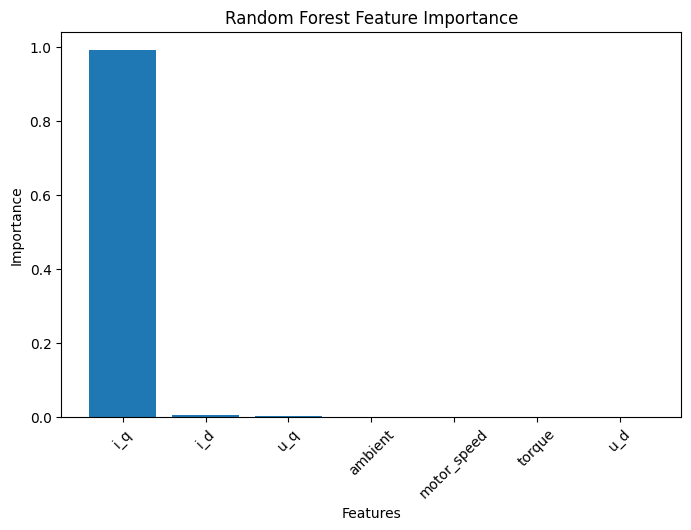

In [29]:
plt.figure(figsize=(8, 5))

plt.bar(
    importance['Feature'],
    importance['Importance']
)

plt.xlabel("Features")
plt.ylabel("Importance")

plt.title(
    "Random Forest Feature Importance"
)

plt.xticks(rotation=45)

plt.show()

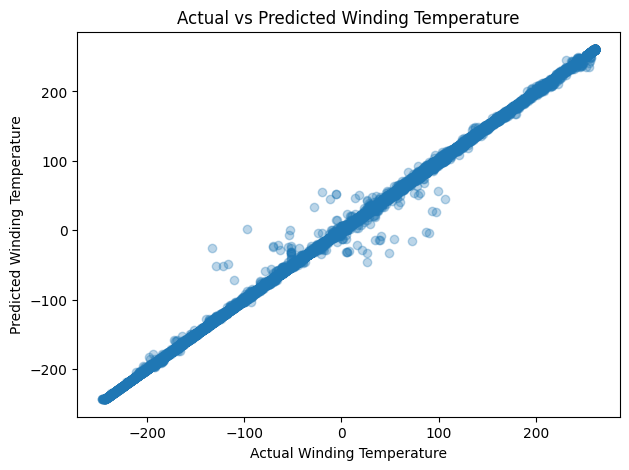

In [30]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    rf_prediction,
    alpha=0.3
)

plt.xlabel(
    "Actual Winding Temperature"
)

plt.ylabel(
    "Predicted Winding Temperature"
)

plt.title(
    "Actual vs Predicted Winding Temperature"
)

plt.show()